In [39]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.random as ran

from Solver2D import *
from bessel_initial_condition import radial_bessel_rho


from matplotlib.colors import LinearSegmentedColormap

# Define colors
colors = ["#ffffff", "dodgerblue"]  # white → dodgerblue

# Create colormap
cblues = LinearSegmentedColormap.from_list(
    "white_to_dodgerblue",
    colors
)

colors2 = ["#ffffff", "steelblue"]  # white → dodgerblue

# Create colormap
creds = LinearSegmentedColormap.from_list(
    "white_to_tomato",
    colors2
)



In [4]:
# Figure 3D
dx = .2
mu = -1.5

tau = 1e-4/2
dt = tau

Lx = 20
Ly = 20

Nx = int(Lx/dx)
Ny = int(Ly/dx)
print(Nx,Ny)

tmax = 101

xspan = np.linspace(-Lx + dx/2, Lx - dx/2, int(2*Nx))
yspan = np.linspace(-Ly + dx/2, Ly - dx/2, int(2*Ny))

X,Y = np.meshgrid(xspan, yspan)

#init_rho = (abs(X) < 4)*(1 + .1*np.cos(Y*2*np.pi/Ly))*.95

init_rho = (abs(X) < 4 + .2*np.cos(Y*2*np.pi/Ly*2))*1

#init_rho = (abs(X) < 4 )*(.98 + 0.02*ran.uniform(-1,1,X.shape))


#init_rho, L = radial_bessel_rho(mu, dx) 
#N = int(L/dx/2)

tspan, rhos = splitting_solver_2d(init_rho, mu, tmax=tmax, dt=dt, dx=dx, proliferation = True)

100 100
100.75300000278288

[np.float64(0.0), np.float64(45.111662531017366), np.float64(89.97270471464019)]


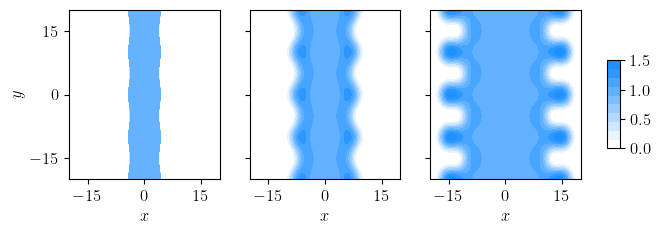

45.111662531017366 89.97270471464019


In [19]:
from matplotlib import rcParams
params = {'legend.fontsize': 'medium',
         'axes.labelsize': 'large',
         'axes.titlesize':'medium',
         'xtick.labelsize':'large',
         'ytick.labelsize':'large',
         'font.family': 'sans-serif',
         'text.usetex': True}
rcParams.update(params)

#X,Y,rhos,tspan,mu = np.load('mu-1.5_2D.npy', allow_pickle = True)

tspan = np.linspace(0,tmax,len(rhos))
a = 2.2
fig, ax = plt.subplots(1,3, figsize = ((Ly/Lx)*a*3,a))

k1, k2, k3 = 0,180,-45

print([tspan[k] for k in [k1,k2,k3]])

ax[0].contourf(X,Y,rhos[k1],10, cmap = cblues, vmin = 0.1, vmax = 1.35)
ax[1].contourf(X,Y,rhos[k2],10, cmap = cblues, vmin = 0.1, vmax = 1.35)
cb = ax[2].contourf(X,Y,rhos[k3]+1e-3,10, cmap = cblues, vmin = 0.1, vmax = 1.35)

for i in range(len(ax)):
    ax[i].set_xticks([-15,0,15])
    ax[i].set_yticks([-15,0,15])
    ax[i].set_xlabel('$x$')
    

    if i > 0:
        ax[i].set_yticklabels([])
 
ax[0].set_ylabel("$y$")

cax = fig.add_axes([.94, 0.25, 0.02, 0.4])
fig.colorbar(cb, cax=cax, extend = 'upper', ticks = [0,.5,1,1.5])

#plt.savefig('constantadhesionfront_mu-1.5.pdf', bbox_inches="tight", pad_inches=0.02)
plt.show()

print(tspan[k2],tspan[k3])

In [ ]:
# Figure 4A
dx = .2
mu = -4

tau = 1e-5
dt = tau

Lx = 20
Ly = 20

Nx = int(Lx/dx)
Ny = int(Ly/dx)
print(Nx,Ny)

tmax = 201

xspan = np.linspace(-Lx + dx/2, Lx - dx/2, int(2*Nx))
yspan = np.linspace(-Ly + dx/2, Ly - dx/2, int(2*Ny))

X,Y = np.meshgrid(xspan, yspan)

init_rho = (abs(X) < 4 + .2*np.cos(Y*2*np.pi/Ly*2))*1

tspan, rhos = splitting_solver_2d(init_rho, mu, tmax=tmax, dt=dt, dx=dx, proliferation = True)

100 100
0.50000000000035935

[np.float64(0.0), np.float64(30.722277722277724), np.float64(120.78071928071928)]


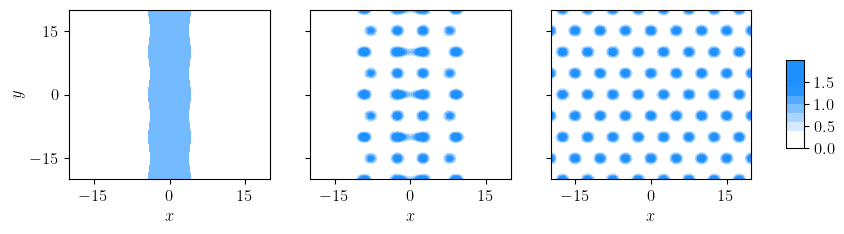

30.722277722277724 120.78071928071928


In [122]:
from matplotlib import rcParams
params = {'legend.fontsize': 'medium',
         'axes.labelsize': 'large',
         'axes.titlesize':'medium',
         'xtick.labelsize':'large',
         'ytick.labelsize':'large',
         'font.family': 'sans-serif',
         'text.usetex': True}
rcParams.update(params)

X,Y = np.meshgrid(xspan, yspan)


tspan = np.linspace(0,tmax,len(rhos))
a = 2.2
fig, ax = plt.subplots(1,3, figsize = ((Ly/Lx)*a*4,a))

k1, k2, k3 = 0,306,-800
print([tspan[k] for k in [k1,k2,k3]])

ax[0].contourf(X,Y,rhos[k1],10, cmap = cblues, vmin = 0.3, vmax = 1.35)
ax[1].contourf(X,Y,rhos[k2],10, cmap = cblues, vmin = 0.3, vmax = 1.35)
cb = ax[2].contourf(X,Y,rhos[k3]+1e-3,10, cmap = cblues, vmin = 0.3, vmax = 1.35)

for i in range(len(ax)):
    ax[i].set_xticks([-15,0,15])
    ax[i].set_yticks([-15,0,15])
    ax[i].set_xlabel('$x$')
    

    if i > 0:
        ax[i].set_yticklabels([])
 
ax[0].set_ylabel("$y$")

cax = fig.add_axes([.94, 0.25, 0.02, 0.4])
fig.colorbar(cb, cax=cax, extend = 'upper', ticks = [0,.5,1,1.5])

plt.savefig('fig4a.pdf', bbox_inches="tight", pad_inches=0.02)
plt.show()

print(tspan[k2],tspan[k3])

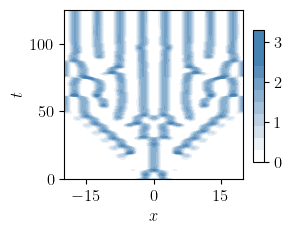

In [123]:
X,T = np.meshgrid(xspan,tspan)

fig, ax = plt.subplots(1,1, figsize = (a*1.05,a))

cb = ax.contourf(X,T,rhos[:,Nx,:],10, vmin = 0.2, vmax = 2.5,  cmap = creds)
cax = fig.add_axes([.94, 0.19, 0.05, 0.6])
fig.colorbar(cb, cax=cax, extend = 'upper', ticks = [0,1,2,3])

ax.set_xlabel('$x$')
ax.set_ylabel('$t$')
ax.set_xticks([-15,0,15])
ax.set_yticks([0,50,100])
ax.set_ylim(0,125)

plt.savefig('fig4b.pdf', bbox_inches="tight", pad_inches=0.02)
plt.show()

In [114]:
len(rhos)

2003